# 04 — Perfis, explicações e visões de negócio

**Entradas:** `rfm_clusters.csv`, `rfm_scaled.csv` e `transactions_clean.csv` (notebooks 01 a 03)
**Saídas (pasta `app/data/`, usada pelo dashboard):** `rfm_segmentos.csv`, `segmentos_resumo.csv` e `receita_cliente_mes.csv`

Este é o notebook que transforma o modelo em **resultado de negócio**: dar nome a cada grupo, explicar por que ele existe, dizer o que fazer com ele e mostrar como ele se comporta **no tempo** e **por país**.

**Objetivos**
1. Descrever cada cluster (tamanho, peso na receita, comportamento)
2. Sugerir um nome para cada segmento, com opção de ajuste manual
3. **Explicar por que cada grupo existe**, com texto gerado a partir dos números
4. Associar uma ação de marketing e um indicador de sucesso a cada segmento
5. Dimensionar o impacto com uma simulação simples e transparente
6. Montar as visões **por tempo** e **por país**
7. Exportar tudo para o dashboard

## 1. Configuração e carga

In [10]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

sns.set_theme(style="whitegrid")
pd.options.display.float_format = "{:,.2f}".format
pd.options.display.max_colwidth = 80

PROCESSED = Path("../data/processed")
REPORTS = Path("../reports")
FIGURES = REPORTS / "figures"
APP_DATA = Path("../app/data")
FIGURES.mkdir(parents=True, exist_ok=True)
APP_DATA.mkdir(parents=True, exist_ok=True)

CLUSTER_COL = "Cluster_KMeans"   # modelo escolhido no notebook 03

res = pd.read_csv(PROCESSED / "rfm_clusters.csv", index_col="CustomerID")
X_df = pd.read_csv(PROCESSED / "rfm_scaled.csv", index_col="CustomerID")

print(f"{len(res):,} clientes | {res[CLUSTER_COL].nunique()} clusters ({CLUSTER_COL})")

5,853 clientes | 4 clusters (Cluster_KMeans)


## 2. Perfil numérico dos clusters

Os clusters estão ordenados por valor: o **0 é o de maior valor monetário mediano**.

In [11]:
perfil = (
    res.groupby(CLUSTER_COL)
    .agg(
        clientes=("Recency", "size"),
        recencia_mediana=("Recency", "median"),
        frequencia_mediana=("Frequency", "median"),
        valor_mediano=("Monetary", "median"),
        valor_total=("Monetary", "sum"),
    )
    .assign(pct_clientes=lambda d: d["clientes"] / d["clientes"].sum() * 100)
    .assign(pct_receita=lambda d: d["valor_total"] / d["valor_total"].sum() * 100)
    .assign(valor_por_cliente=lambda d: d["valor_total"] / d["clientes"])
)

z = X_df.groupby(res[CLUSTER_COL]).mean().add_prefix("z_")
perfil = perfil.join(z)
perfil

,clientes,recencia_mediana,frequencia_mediana,valor_mediano,valor_total,pct_clientes,pct_receita,valor_por_cliente,z_Recency,z_Frequency,z_Monetary
Cluster_KMeans,,,,,,,,,,,
0,1115,15.00,13.00,"5,115.36","12,322,405.08",19.05,72.14,"11,051.48",-1.14,1.54,1.36
1,1477,158.00,5.00,"1,569.36","3,069,323.28",25.23,17.97,"2,078.08",0.39,0.29,0.43
2,1219,23.00,3.00,706.02,"1,001,859.33",20.83,5.86,821.87,-0.88,-0.31,-0.24
3,2042,400.00,1.00,289.59,"688,498.08",34.89,4.03,337.17,0.86,-0.86,-0.91


## 3. Nomeando os segmentos

A função abaixo sugere um nome olhando as médias **padronizadas** de cada cluster (`z_Recency`, `z_Frequency`, `z_Monetary`). Lembre que em Recency **valor alto é ruim** (faz tempo que o cliente não compra).

Os limites são simples e estão no código para você poder mudar. **Revise os nomes sugeridos**: eles são um ponto de partida, e o seu julgamento sobre o negócio vale mais do que a regra.

In [12]:
def sugerir_nome(z_r, z_f, z_m):
    valor_alto = (z_f > 0.5) and (z_m > 0.5)
    valor_baixo = (z_f < -0.3) and (z_m < -0.3)
    recente = z_r < -0.3
    antigo = z_r > 0.3

    if valor_alto and recente:
        return "Campeões"
    if valor_alto and antigo:
        return "Valiosos em risco"
    if valor_alto:
        return "Grandes clientes"
    if valor_baixo and antigo:
        return "Inativos"
    if valor_baixo and recente:
        return "Novos e ocasionais"
    if antigo:
        return "Em risco"
    if recente:
        return "Leais em crescimento"
    return "Regulares"


nomes = {
    c: sugerir_nome(r.z_Recency, r.z_Frequency, r.z_Monetary)
    for c, r in perfil.iterrows()
}

# Se dois clusters receberem o mesmo nome, acrescenta o número do cluster
repetidos = pd.Series(nomes).value_counts()
nomes = {c: (n if repetidos[n] == 1 else f"{n} ({c})") for c, n in nomes.items()}
nomes

{0: 'Campeões', 1: 'Em risco', 2: 'Leais em crescimento', 3: 'Inativos'}

**Ajuste manual (opcional):** se discordar de algum nome, preencha o dicionário abaixo com `{número_do_cluster: "Nome"}` e rode a célula. Exemplo: `{0: "Clientes VIP", 3: "Perdidos"}`.

In [13]:
NOMES_MANUAIS = {}   # <- ex.: {0: "Clientes VIP"}

nomes.update(NOMES_MANUAIS)
perfil["segmento"] = perfil.index.map(nomes)
perfil[["segmento", "clientes", "pct_clientes", "pct_receita", "recencia_mediana", "frequencia_mediana", "valor_mediano"]]

,segmento,clientes,pct_clientes,pct_receita,recencia_mediana,frequencia_mediana,valor_mediano
Cluster_KMeans,,,,,,,
0,Campeões,1115,19.05,72.14,15.00,13.00,"5,115.36"
1,Em risco,1477,25.23,17.97,158.00,5.00,"1,569.36"
2,Leais em crescimento,1219,20.83,5.86,23.00,3.00,706.02
3,Inativos,2042,34.89,4.03,400.00,1.00,289.59


## 4. Por que cada grupo existe

Cada segmento ganha três textos, todos gerados a partir dos números do próprio cluster:
- **`distintivo`**: o que diferencia o grupo da média da base (usando os valores padronizados)
- **`explicacao_dados`**: o perfil em números, sempre comparado com a base inteira
- **`porque_existe`**: o motivo de negócio para tratar o grupo à parte

> Esses textos **descrevem padrões**, não causas. Eles dizem *como* o grupo se comporta e por que faz sentido separá-lo, mas não explicam *por que* os clientes se comportam assim. Se você renomeou algum segmento, escreva o `porque_existe` dele em `PORQUE` (sem isso, o notebook usa a descrição automática).

In [14]:
base_med = res[["Recency", "Frequency", "Monetary"]].median()


def descrever(z_r, z_f, z_m):
    r = ("compraram há pouco tempo" if z_r < -0.5
         else "estão há muito tempo sem comprar" if z_r > 0.5
         else "têm recência próxima da média")
    f = ("compram com muita frequência" if z_f > 0.5
         else "compram poucas vezes" if z_f < -0.5
         else "têm frequência próxima da média")
    m = ("gastam bastante" if z_m > 0.5
         else "gastam pouco" if z_m < -0.5
         else "têm gasto próximo da média")
    return f"Reúne clientes que {r}, {f} e {m}."


def em_numeros(r):
    vezes = r.valor_mediano / base_med["Monetary"]   # mediana: a média é distorcida por poucos clientes enormes
    return (
        f"Mediana de {r.recencia_mediana:,.0f} dias desde a última compra (base: {base_med['Recency']:,.0f}), "
        f"{r.frequencia_mediana:,.0f} notas fiscais (base: {base_med['Frequency']:,.0f}) e gasto mediano de "
        f"{r.valor_mediano:,.0f} (base: {base_med['Monetary']:,.0f}). "
        f"Representa {r.pct_clientes:.1f}% dos clientes e {r.pct_receita:.1f}% da receita; "
        f"o gasto mediano de um cliente do grupo é {vezes:.1f}x o gasto mediano da base."
    )


PORQUE = {
    "Campeões": (
        "É o núcleo da receita: clientes que compram com frequência, gastam muito e compraram recentemente. "
        "Foi separado para receber tratamento próprio, porque perdê-lo custa muito mais do que perder qualquer outro grupo."
    ),
    "Grandes clientes": (
        "Gasta muito e compra com frequência, mas não comprou tão recentemente. "
        "O padrão pode indicar perfil de atacado ou revenda, com ciclo de compra mais espaçado."
    ),
    "Valiosos em risco": (
        "Já foi um grupo de alto valor, mas está há muito tempo sem comprar. "
        "Existe como segmento à parte porque é onde mais dinheiro pode ser perdido (ou recuperado) com uma ação de retenção."
    ),
    "Leais em crescimento": (
        "Compra de forma recente e regular, ainda sem o volume dos grupos de maior valor. "
        "É o grupo com mais chance de subir de patamar com incentivo certo."
    ),
    "Novos e ocasionais": (
        "Compra pouco e gasta pouco, mas comprou há pouco tempo. "
        "Mistura clientes recém-chegados e compradores eventuais; a pergunta aqui é quantos voltam a comprar."
    ),
    "Em risco": (
        "Já comprou com alguma regularidade, mas está há bastante tempo sem voltar. "
        "Existe para separar quem ainda pode ser reativado antes de virar inativo."
    ),
    "Inativos": (
        "Comprou pouco e há muito tempo. Costuma ser o grupo com mais clientes e menos receita, "
        "e serve para decidir quanto vale (ou não) investir em reativação."
    ),
    "Regulares": (
        "Fica no meio-termo, sem sinais fortes de alto valor nem de abandono. "
        "Existe para não misturar o cliente médio com grupos de comportamento extremo."
    ),
}


def porque_para(nome, distintivo):
    base = nome.split(" (")[0]          # remove o sufixo " (n)" se existir
    return PORQUE.get(nome) or PORQUE.get(base) or distintivo


perfil["distintivo"] = [descrever(r.z_Recency, r.z_Frequency, r.z_Monetary) for _, r in perfil.iterrows()]
perfil["explicacao_dados"] = [em_numeros(r) for _, r in perfil.iterrows()]
perfil["porque_existe"] = [porque_para(n, d) for n, d in zip(perfil["segmento"], perfil["distintivo"])]

for _, r in perfil.iterrows():
    print(f"■ {r.segmento}")
    print(f"  Por que existe:  {r.porque_existe}")
    print(f"  O que distingue: {r.distintivo}")
    print(f"  Em números:      {r.explicacao_dados}")
    print()

■ Campeões
  Por que existe:  É o núcleo da receita: clientes que compram com frequência, gastam muito e compraram recentemente. Foi separado para receber tratamento próprio, porque perdê-lo custa muito mais do que perder qualquer outro grupo.
  O que distingue: Reúne clientes que compraram há pouco tempo, compram com muita frequência e gastam bastante.
  Em números:      Mediana de 15 dias desde a última compra (base: 95), 13 notas fiscais (base: 3) e gasto mediano de 5,115 (base: 856). Representa 19.1% dos clientes e 72.1% da receita; o gasto mediano de um cliente do grupo é 6.0x o gasto mediano da base.

■ Em risco
  Por que existe:  Já comprou com alguma regularidade, mas está há bastante tempo sem voltar. Existe para separar quem ainda pode ser reativado antes de virar inativo.
  O que distingue: Reúne clientes que têm recência próxima da média, têm frequência próxima da média e têm gasto próximo da média.
  Em números:      Mediana de 158 dias desde a última compra (base: 95), 5 

## 5. Ação recomendada por segmento

Cada segmento recebe uma **ação** e um **indicador de sucesso**. As ações são padrões de CRM amplamente usados; adapte ao contexto da empresa. Se você renomeou algum segmento, acrescente a entrada dele em `ACOES`.

In [15]:
ACOES = {
    "Campeões": (
        "Programa de fidelidade/VIP, acesso antecipado a lançamentos e pedido de indicações.",
        "Retenção e valor médio por cliente",
    ),
    "Grandes clientes": (
        "Atendimento dedicado e condições especiais por volume (perfil de atacado).",
        "Taxa de recompra",
    ),
    "Valiosos em risco": (
        "Contato proativo e oferta personalizada de reativação. É o grupo com mais dinheiro em jogo.",
        "Taxa de reativação",
    ),
    "Leais em crescimento": (
        "Venda cruzada e incentivo à próxima compra, como frete grátis acima de um valor.",
        "Frequência de compra",
    ),
    "Novos e ocasionais": (
        "Sequência de boas-vindas e oferta para estimular a segunda compra.",
        "Taxa de segunda compra",
    ),
    "Em risco": (
        "Campanha de reengajamento com lembrete e desconto por tempo limitado.",
        "Taxa de reativação",
    ),
    "Inativos": (
        "Campanha de baixo custo; testar uma última oferta e depois reduzir o investimento.",
        "Custo por reativação",
    ),
    "Regulares": (
        "Comunicação periódica com recomendações baseadas no histórico de compra.",
        "Taxa de conversão do e-mail",
    ),
}


def acao_para(nome):
    base = nome.split(" (")[0]
    return ACOES.get(nome) or ACOES.get(base) or ("Definir ação para este segmento.", "Definir indicador")


perfil["acao_recomendada"] = perfil["segmento"].map(lambda n: acao_para(n)[0])
perfil["indicador"] = perfil["segmento"].map(lambda n: acao_para(n)[1])

cartao = perfil[
    ["segmento", "clientes", "pct_clientes", "pct_receita", "recencia_mediana",
     "frequencia_mediana", "valor_mediano", "valor_por_cliente",
     "z_Recency", "z_Frequency", "z_Monetary",
     "porque_existe", "distintivo", "explicacao_dados",
     "acao_recomendada", "indicador"]
]
cartao[["segmento", "clientes", "pct_clientes", "pct_receita", "valor_por_cliente", "acao_recomendada", "indicador"]]

,segmento,clientes,pct_clientes,pct_receita,valor_por_cliente,acao_recomendada,indicador
Cluster_KMeans,,,,,,,
0,Campeões,1115,19.05,72.14,"11,051.48","Programa de fidelidade/VIP, acesso antecipado a lançamentos e pedido de indi...",Retenção e valor médio por cliente
1,Em risco,1477,25.23,17.97,"2,078.08",Campanha de reengajamento com lembrete e desconto por tempo limitado.,Taxa de reativação
2,Leais em crescimento,1219,20.83,5.86,821.87,"Venda cruzada e incentivo à próxima compra, como frete grátis acima de um va...",Frequência de compra
3,Inativos,2042,34.89,4.03,337.17,Campanha de baixo custo; testar uma última oferta e depois reduzir o investi...,Custo por reativação


## 6. Visualizações do perfil

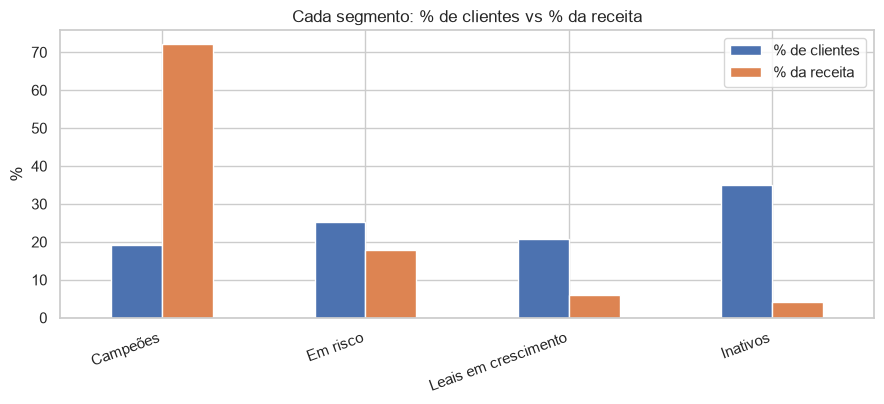

In [16]:
ordem = perfil["segmento"].tolist()

fig, ax = plt.subplots(figsize=(9, 4.2))
plot_df = perfil.set_index("segmento")[["pct_clientes", "pct_receita"]].loc[ordem]
plot_df.plot.bar(ax=ax)
ax.set_title("Cada segmento: % de clientes vs % da receita")
ax.set_xlabel("")
ax.set_ylabel("%")
ax.legend(["% de clientes", "% da receita"])
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
fig.savefig(FIGURES / "04_clientes_vs_receita.png", dpi=150)
plt.show()

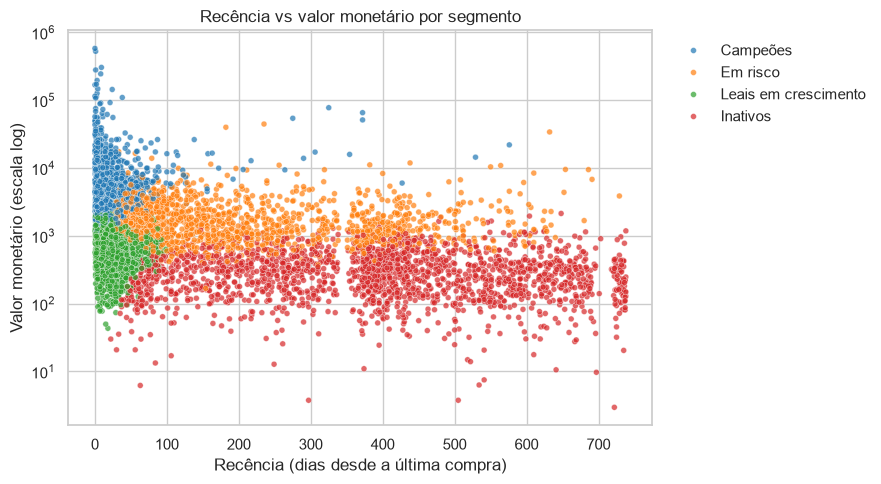

In [17]:
res["Segmento"] = res[CLUSTER_COL].map(nomes)

fig, ax = plt.subplots(figsize=(9, 5))
sns.scatterplot(
    data=res.reset_index(),
    x="Recency", y="Monetary", hue="Segmento", hue_order=ordem,
    palette="tab10", s=18, alpha=0.7, ax=ax,
)
ax.set_yscale("log")
ax.set_title("Recência vs valor monetário por segmento")
ax.set_xlabel("Recência (dias desde a última compra)")
ax.set_ylabel("Valor monetário (escala log)")
ax.legend(bbox_to_anchor=(1.02, 1), loc="upper left", frameon=False)
plt.tight_layout()
fig.savefig(FIGURES / "04_segmentos_scatter.png", dpi=150, bbox_inches="tight")
plt.show()

## 7. Dimensionando o impacto (simulação)

> **Isto é uma simulação com premissa assumida, não um resultado do modelo.** Serve para mostrar o raciocínio de negócio: quanto dinheiro está em jogo se uma campanha de reativação funcionar em parte do segmento. A taxa abaixo é **hipotética**; no mundo real ela viria de um teste A/B.

In [18]:
TAXA_REATIVACAO = 0.10   # premissa: 10% do segmento volta a comprar (hipótese)

alvos = perfil[perfil["segmento"].str.contains("risco")]

if alvos.empty:
    print("Nenhum segmento com 'risco' no nome. Defina a variável alvos manualmente.")
else:
    sim = alvos[["segmento", "clientes", "valor_por_cliente"]].copy()
    sim["clientes_reativados"] = sim["clientes"] * TAXA_REATIVACAO
    sim["receita_estimada"] = sim["clientes_reativados"] * sim["valor_por_cliente"]
    total = res["Monetary"].sum()
    print(f"Premissa: {TAXA_REATIVACAO:.0%} de reativação")
    display(sim)
    print(f"Receita estimada recuperada: {sim['receita_estimada'].sum():,.0f} "
          f"({sim['receita_estimada'].sum() / total:.1%} da receita total do período)")

Premissa: 10% de reativação


,segmento,clientes,valor_por_cliente,clientes_reativados,receita_estimada
Cluster_KMeans,,,,,
1,Em risco,1477,"2,078.08",147.70,"306,932.33"


Receita estimada recuperada: 306,932 (1.8% da receita total do período)


O `valor_por_cliente` é o gasto acumulado durante **todo o período** (dois anos), então a estimativa acima é um **teto de referência**, não uma previsão. Comente essa limitação no README.

## 8. Visão no tempo e por país

Aqui voltamos às transações para responder duas perguntas:
- **Como cada segmento se comportou ao longo do tempo?**
- **Como os segmentos se distribuem entre os países?**

Para isso, cada cliente ganha: o **país principal** (onde mais comprou), a data da **primeira** e da **última** compra. Também montamos uma tabela cliente × mês, pequena o suficiente para ir ao GitHub e alimentar o dashboard.

> **Duas ressalvas para registrar no README:**
> 1. O segmento é definido com o **período inteiro**. Os gráficos de tempo mostram, portanto, como os clientes que hoje estão em cada segmento se comportaram no passado (visão retrospectiva). Um cliente "Inativo" hoje pode ter sido ativo em 2010.
> 2. Quem comprou no primeiro mês do período pode já ser cliente antigo. O primeiro mês do gráfico de entrada de clientes, portanto, está inflado.

In [19]:
tx = pd.read_csv(
    PROCESSED / "transactions_clean.csv",
    usecols=["Invoice", "InvoiceDate", "CustomerID", "Country", "Revenue"],
    parse_dates=["InvoiceDate"],
    dtype={"Invoice": str},
)

pais_principal = tx.groupby("CustomerID")["Country"].agg(lambda s: s.mode().iat[0])
datas = tx.groupby("CustomerID").agg(
    PrimeiraCompra=("InvoiceDate", "min"),
    UltimaCompra=("InvoiceDate", "max"),
)
datas = datas.apply(lambda c: c.dt.normalize())

res = res.join(pais_principal).join(datas)
print("Clientes sem país:", res["Country"].isna().sum())

tx["Mes"] = tx["InvoiceDate"].dt.to_period("M").dt.to_timestamp()
cliente_mes = (
    tx.groupby(["CustomerID", "Mes"])
    .agg(receita=("Revenue", "sum"), notas=("Invoice", "nunique"))
    .reset_index()
)
print(f"Tabela cliente x mês: {len(cliente_mes):,} linhas")

Clientes sem país: 0
Tabela cliente x mês: 25,507 linhas


### Evolução mensal por segmento

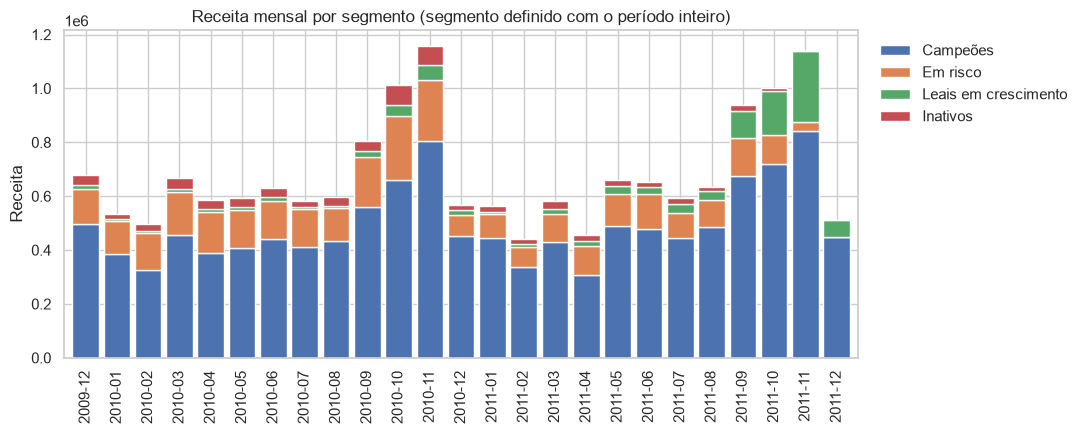

In [20]:
m = cliente_mes.merge(res[["Segmento"]], left_on="CustomerID", right_index=True)

mensal = (
    m.pivot_table(index="Mes", columns="Segmento", values="receita", aggfunc="sum")
    .reindex(columns=ordem)
    .fillna(0)
)
mensal.index = mensal.index.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(11, 4.5))
mensal.plot.bar(stacked=True, ax=ax, width=0.85)
ax.set_title("Receita mensal por segmento (segmento definido com o período inteiro)")
ax.set_xlabel("")
ax.set_ylabel("Receita")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
fig.savefig(FIGURES / "04_receita_mensal_segmento.png", dpi=150, bbox_inches="tight")
plt.show()

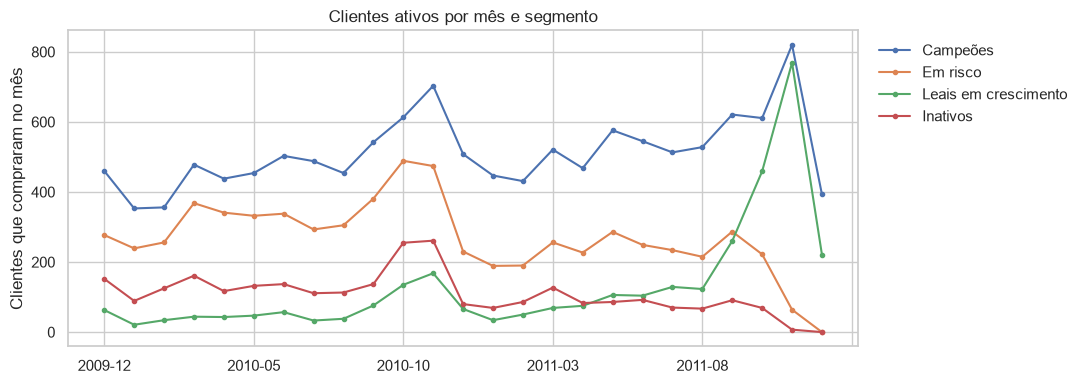

In [21]:
ativos = (
    m.groupby(["Mes", "Segmento"])["CustomerID"].nunique()
    .unstack(fill_value=0)
    .reindex(columns=ordem, fill_value=0)
)
ativos.index = ativos.index.strftime("%Y-%m")

fig, ax = plt.subplots(figsize=(11, 4))
ativos.plot(ax=ax, marker="o", markersize=3)
ax.set_title("Clientes ativos por mês e segmento")
ax.set_xlabel("")
ax.set_ylabel("Clientes que compraram no mês")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
plt.show()

Procure por **sazonalidade** (picos no fim do ano) e por segmentos cujos clientes ativos caem ao longo do tempo: é a assinatura de um grupo que está esfriando.

### Distribuição por país

In [22]:
top_paises = res["Country"].value_counts().head(8).index

comp = (
    res[res["Country"].isin(top_paises)]
    .groupby(["Country", "Segmento"]).size()
    .unstack(fill_value=0)
    .reindex(columns=ordem, fill_value=0)
    .loc[top_paises]
)
comp.assign(total=comp.sum(axis=1))

Segmento,Campeões,Em risco,Leais em crescimento,Inativos,total
Country,,,,,
United Kingdom,1014,1327,1104,1889,5334
Germany,26,32,30,18,106
France,26,15,22,31,94
Spain,5,5,14,11,35
Belgium,7,9,5,7,28
Portugal,4,6,7,6,23
Switzerland,3,13,3,3,22
Netherlands,3,6,3,10,22


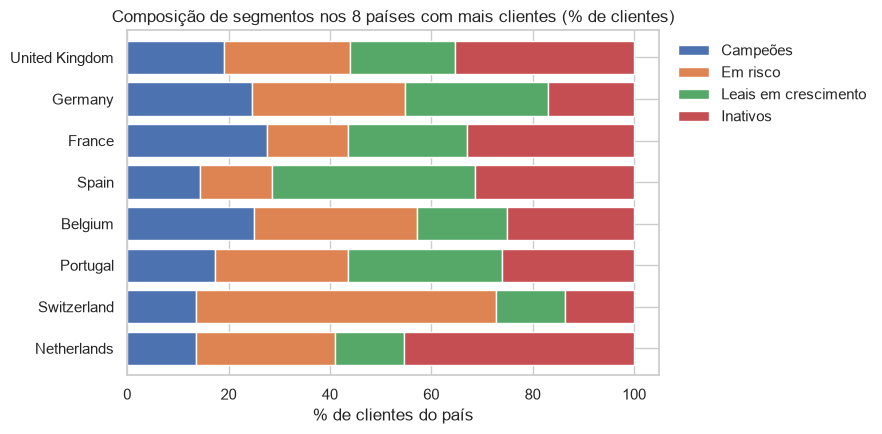

In [23]:
comp_pct = comp.div(comp.sum(axis=1), axis=0) * 100

fig, ax = plt.subplots(figsize=(9, 4.5))
comp_pct.loc[top_paises[::-1]].plot.barh(stacked=True, ax=ax, width=0.8)
ax.set_title("Composição de segmentos nos 8 países com mais clientes (% de clientes)")
ax.set_xlabel("% de clientes do país")
ax.set_ylabel("")
ax.legend(bbox_to_anchor=(1.01, 1), loc="upper left", frameon=False)
plt.tight_layout()
fig.savefig(FIGURES / "04_paises_segmentos.png", dpi=150, bbox_inches="tight")
plt.show()

Um país domina a base (provavelmente o Reino Unido), então os demais têm **poucos clientes** e percentuais instáveis: um único cliente pode mudar o gráfico. Sempre mostre o `n` ao lado da proporção e comente isso no README.

## 9. Exportando para o dashboard

In [24]:
cols = ["Recency", "Frequency", "Monetary", CLUSTER_COL, "Segmento", "Country", "PrimeiraCompra", "UltimaCompra"]
saida = res[cols]

saida.to_csv(PROCESSED / "rfm_segmentos.csv")
saida.to_csv(APP_DATA / "rfm_segmentos.csv")
cartao.to_csv(APP_DATA / "segmentos_resumo.csv", index=False)
cliente_mes.to_csv(APP_DATA / "receita_cliente_mes.csv", index=False)

print(f"Salvo em {APP_DATA}:")
for f in ["rfm_segmentos.csv", "segmentos_resumo.csv", "receita_cliente_mes.csv"]:
    print(f"  {f}  ({(APP_DATA / f).stat().st_size / 1024:,.0f} KB)")

Salvo em ..\app\data:
  rfm_segmentos.csv  (403 KB)
  segmentos_resumo.csv  (3 KB)
  receita_cliente_mes.csv  (705 KB)


## Conclusões e próximos passos

Escreva aqui, em linguagem de negócio:
- Quais são os segmentos, o peso de cada um em clientes e em receita
- O achado mais importante (por exemplo, "X% dos clientes geram Y% da receita")
- Como os segmentos evoluíram no tempo e se algum está esfriando
- Como a base se distribui entre os países
- A ação prioritária e por quê

**Próximo passo:** abrir o dashboard (`streamlit run app/app.py`) e conferir as cinco abas com os dados reais.